# PH5024 Problem Sheet 1 — Model answers
## Green's functions and quasi-particle interference in a square-lattice tight-binding model

This notebook shows the derivations, code, numerical checks and written answers for the first problem sheet of TOP SUPA

First assumption made: In question one states:"Plot the band... the Brillouin **one**.." which I assume is supposed to be **zone**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ellipkm1
from scipy.integrate import quad_vec

plt.rcParams["figure.dpi"] = 90

t   = 0.1     # nearest-neighbour hopping (eV)
a   = 1.0     # lattice constant (all lengths in units of a) asusming a=1 → Wavevectors in 1/a; plots use units of \pi/a.
eta = 0.01    # broadening (eV)

integrate = getattr(np, "trapezoid", None)

---
# Question 1: Band structure and Fermi surface

## 1.1 Derivation of the dispersion relation

Label the lattice sites by $\mathbf{R}$ and let $|\mathbf{R}\rangle$ be an electron on site $\mathbf{R}$. The four nearest-neighbour vectors are given by:
$$\boldsymbol{\delta}\in\{(a,0),\ (-a,0),\ (0,a),\ (0,-a)\}.$$
Nearest-neighbour hopping states
$$H = -t\sum_{\mathbf{R}}\sum_{\boldsymbol\delta}|\mathbf{R}+\boldsymbol\delta\rangle\langle\mathbf{R}|, \qquad\text{so}\qquad H|\mathbf{R}\rangle = -t\sum_{\boldsymbol\delta}|\mathbf{R}+\boldsymbol\delta\rangle .$$

**Bloch states.** On an $N\times N$ lattice with periodic boundary conditions, define
$$|\mathbf{k}\rangle = \frac{1}{N}\sum_{\mathbf{R}} e^{i\mathbf{k}\cdot\mathbf{R}}|\mathbf{R}\rangle .$$
The prefactor $1/N = 1/\sqrt{N^2}$ normalises the state over $N^2$ sites.

**Apply $H$.**
$$H|\mathbf{k}\rangle = \frac{1}{N}\sum_{\mathbf{R}} e^{i\mathbf{k}\cdot\mathbf{R}}\left(-t\sum_{\boldsymbol\delta}|\mathbf{R}+\boldsymbol\delta\rangle\right).$$
Relabel the sum with $\mathbf{R}' = \mathbf{R}+\boldsymbol\delta$, so that $e^{i\mathbf{k}\cdot\mathbf{R}} = e^{i\mathbf{k}\cdot\mathbf{R}'}e^{-i\mathbf{k}\cdot\boldsymbol\delta}$. Because of the periodic boundary conditions, $\mathbf{R}'$ runs over all sites:
$$H|\mathbf{k}\rangle = -t\left(\sum_{\boldsymbol\delta}e^{-i\mathbf{k}\cdot\boldsymbol\delta}\right)\frac1N\sum_{\mathbf{R}'}e^{i\mathbf{k}\cdot\mathbf{R}'}|\mathbf{R}'\rangle = -t\left(\sum_{\boldsymbol\delta}e^{-i\mathbf{k}\cdot\boldsymbol\delta}\right)|\mathbf{k}\rangle .$$
Thus $|\mathbf{k}\rangle$ is an eigenstate.

Evaluating the sum. Pair up $\pm\boldsymbol\delta$ using $e^{ix}+e^{-ix} = 2\cos x$:
$$\sum_{\boldsymbol\delta}e^{-i\mathbf{k}\cdot\boldsymbol\delta} = \left(e^{-ik_xa}+e^{ik_xa}\right) + \left(e^{-ik_ya}+e^{ik_ya}\right) = 2\cos k_xa + 2\cos k_ya .$$
Thus
$$\boxed{\varepsilon_\mathbf{k} = -2t\left(\cos k_xa + \cos k_ya\right)}$$
which is Eq. (86) of the notes.

In [2]:
def dispersion(kx, ky, t=t, a=a):
    # Band energy eps(k) in eV; kx, ky in units of 1/a (numbers or numpy arrays).
    return -2.0 * t * (np.cos(kx * a) + np.cos(ky * a))

## 1.2 Analytic behaviour along the path

Values at the high-symmetry points, using $\cos 0 = 1$ and $\cos\pi = -1$:

| Point | ${k}$ | $\varepsilon_{k}$ |
|---|---|---|
| $\Gamma$ | $(0,0)$ | $-2t(1+1) = -4t = -0.4$ eV (band bottom) |
| $M$ | $(\pi,0)$ | $-2t(-1+1) = 0$ |
| $X$ | $(\pi,\pi)$ | $-2t(-1-1) = +4t = +0.4$ eV (band top) |

The bandwidth is therefore $W = 8t = 0.8$ eV.

Along each segment (with $a=1$):
- $\Gamma\to M$, ${k}=(k,0)$: $\ \varepsilon = -2t(1+\cos k)$. This rises monotonically from $-4t$ to $0$.
- $M\to X$, ${k}=(\pi,k)$: $\ \varepsilon = -2t(-1+\cos k) = 2t(1-\cos k)$. This rises from $0$ to $4t$.
- $X\to\Gamma$, ${k}=(k,k)$: $\ \varepsilon = -4t\cos k$. This falls from $4t$ to $-4t$, crossing zero at ${k}=(\pi/2,\pi/2)$.

Taylor expansions, using $\cos x \approx 1 - x^2/2$ and $\cos(\pi + x) = -\cos x \approx -1 + x^2/2$:

- Near $\Gamma$:
$$\varepsilon \approx -2t\left(2 - \tfrac{k_x^2+k_y^2}{2}\right) = -4t + t\,a^2|{k}|^2 .$$
This is an isotropic, free-electron-like parabola. Comparing this with $\hbar^2k^2/2m^*$ gives the effective mass $m^* = \hbar^2/(2ta^2)$.

- Near $X$, writing ${k} = (\pi,\pi)+{p}$:
$$\varepsilon \approx -2t\left(-2 + \tfrac{p_x^2+p_y^2}{2}\right) = +4t - t\,a^2|{p}|^2 .$$
This is isotropic and a downward parabola, so states near the band top behave as holes.

- Near $M$, writing ${k} = (\pi + p_x, p_y)$:
$$\varepsilon \approx -2t\left[\left(-1+\tfrac{p_x^2}{2}\right) + \left(1-\tfrac{p_y^2}{2}\right)\right] = t\,a^2\left(p_y^2 - p_x^2\right).$$
This is a saddle point. For $\Gamma\to M$ (varying $p_x$) the energy has a maximum at $M$. Along $M\to X$ (varying $p_y$) it has a minimum. In both directions the slope at $M$ is zero.

This is particle–hole symmetry. Since $\cos(x+\pi) = -\cos x$,
$$\varepsilon_{{k}+{Q}} = -\varepsilon_{k}, \qquad {Q} = (\pi,\pi)/a .$$
The band is therefore symmetric about $\varepsilon = 0$.

## 1.3 Numerical band structure

Building the path. A straight segment from ${A}$ to ${B}$ is ${k}(s) = {A} + s({B}-{A})$ with $0\le s<1$. Defining and using `endpoint=False` will avoid repeating each corner. The number of points on a segment is proportional to its length ($1$, $1$ and $\sqrt2$ in units of $\pi/a$), so the $k$-spacing is uniform.

Horizontal axis. We plot against the overall distance travelled along the path, so that slopes give group velocities. The corners then sit at $0$, $1$, $2$ and $2+\sqrt2$.

eps(Gamma) = -0.4000 eV
eps(M    ) = -0.0000 eV
eps(X    ) = +0.4000 eV


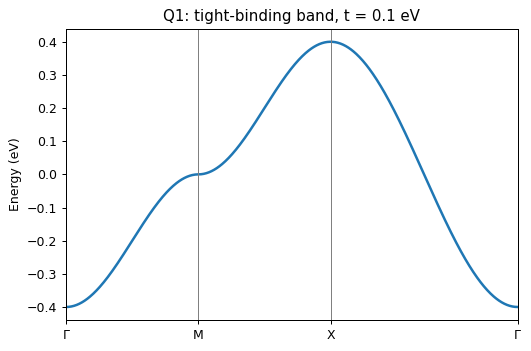

In [3]:
G_pt, M_pt, X_pt = np.array([0.0, 0.0]), np.array([1.0, 0.0]), np.array([1.0, 1.0])   # units of pi/a
corners       = [G_pt, M_pt, X_pt, G_pt]
corner_labels = [r"$\Gamma$", "M", "X", r"$\Gamma$"]


def build_path(corners, n_per_unit=200):
    segs = []
    for A, B in zip(corners[:-1], corners[1:]):
        n = max(2, int(round(n_per_unit * np.linalg.norm(B - A))))
        s = np.linspace(0.0, 1.0, n, endpoint=False)
        segs.append(A + s[:, None] * (B - A))
    segs.append(corners[-1][None, :])
    k_path = np.vstack(segs)
    distance = np.concatenate(([0.0], np.cumsum(np.linalg.norm(np.diff(k_path, axis=0), axis=1))))
    corner_distance = np.concatenate(([0.0], np.cumsum(
        [np.linalg.norm(B - A) for A, B in zip(corners[:-1], corners[1:])])))
    return k_path, distance, corner_distance


k_path, distance, corner_distance = build_path(corners)
eps_path = dispersion(np.pi * k_path[:, 0] / a, np.pi * k_path[:, 1] / a)

for label, k in zip(["Gamma", "M", "X"], [G_pt, M_pt, X_pt]):
    print(f"eps({label:5s}) = {dispersion(np.pi*k[0], np.pi*k[1]):+.4f} eV")   # -0.0000 is rounding (~1e-17)


def decorate_path_axis(ax):
    for d in corner_distance:
        ax.axvline(d, color="grey", lw=0.8)
    ax.set_xticks(corner_distance)
    ax.set_xticklabels(corner_labels)
    ax.set_xlim(corner_distance[0], corner_distance[-1])


fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(distance, eps_path, lw=2)
decorate_path_axis(ax)
ax.set_ylabel("Energy (eV)")
ax.set_title(f"Q1: tight-binding band, t = {t} eV")
fig.tight_layout(); fig.savefig("Q1_band_structure.png", dpi=200); plt.show()

## 1.4 Answer: expected Fermi surface and the changes of $\varepsilon_F$

Reading the Fermi surface off the band structure. The Fermi surface crosses a path segment wherever the band crosses $\varepsilon_F$. Compare two crossings:
- the Fermi wavevector along the axis direction, $k_{ax}$, found on $\Gamma\to M$;
- the Fermi wavevector along the diagonal, $|\mathbf{k}|_{diag}$, found on $X\to\Gamma$.

If $k_{ax} = |\mathbf{k}|_{diag}$ the Fermi surface is closed/round. If different, it is anisotropic.

$\varepsilon_F$ just above $-4t$. The line near $\Gamma$ is an isotropic parabola, so $k_{ax}=|\mathbf{k}|_{diag}$. THus the Fermi surface is a small circle centred on $\Gamma$. It is electron-like: the occupied states are inside it.

As $\varepsilon_F$ rises towards 0. The band rises more slowly along $\Gamma\to M$ than along the diagonal (it flattens out towards the saddle at $M$). So for a given energy the axis crossing moves out faster than the diagonal one, and $k_{ax} > |\mathbf{k}|_{diag}$. The circle turns into a rounded square form whose corners point along the axes, towards $M$.

For example at $\varepsilon_F = -0.2$ eV: on the axis, $\cos k_{ax} = 0$, so $k_{ax} = 0.5\pi/a$. On the diagonal, $\cos k = 1/2$, so $|\mathbf{k}|_{diag} = \sqrt2\,\pi/3a \approx 0.47\pi/a$.

At $\varepsilon_F = 0$, set $\cos k_x + \cos k_y = 0$. Then $\cos k_x = -\cos k_y = \cos(\pi - k_y)$, so $k_x = \pm(\pi - k_y)$, i.e.
$$|k_x| + |k_y| = \pi/a .$$
This is a perfect square rotated by 45 degrees with corners at the saddle points $M$, $(\pm\pi,0)$ and $(0,\pm\pi)$, and straight edges through $(\pm\pi/2,\pm\pi/2)$. Consistently, $k_{ax}\to\pi$ and $|\mathbf{k}|_{diag}\to\pi/\sqrt2$, which exactly is the corner-to-edge ratio of a square. Opposite edges are connected by the single wavevector $\mathbf{Q} = (\pi,\pi)/a$: this is perfect nesting (lecture notes, Section 6).

For $\varepsilon_F > 0$. Now the whole $\Gamma\to M$ segment lies below $\varepsilon_F$, and the band crosses $\varepsilon_F$ on $M\to X$ instead. The Fermi surface no longer encloses $\Gamma$. It now encloses $X = (\pi,\pi)$. These "pockets" are hole-like where the empty states are inside them.

As $\varepsilon_F\to +4t$. The hole pocket shrinks to a small circle around $X$, this is because of the isotropic expansion near $X$ and disappears at the band top.

Particle–hole symmetry. Because $\varepsilon_{\mathbf{k}+\mathbf{Q}} = -\varepsilon_{\mathbf{k}}$, the Fermi surface at $+\varepsilon$ is the same at $-\varepsilon$ but shifted by $\mathbf{Q}$.

The plot below (not required by the sheet, I jus thad AI quickly write me this code) confirms this reasoning by drawing constant-energy contours across the Brillouin zone.

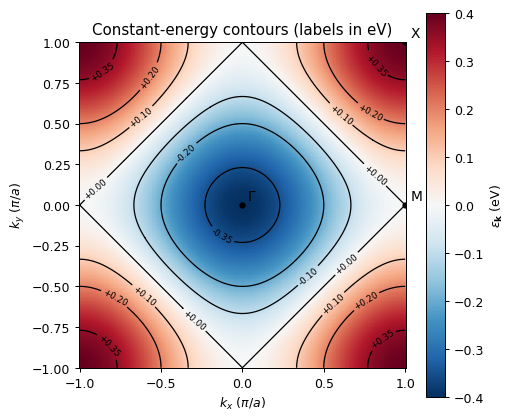

In [4]:
kk = np.linspace(-np.pi, np.pi, 401)
KXc, KYc = np.meshgrid(kk, kk, indexing="ij")
Ec = dispersion(KXc, KYc)
levels = [-0.35, -0.2, -0.1, 0.0, 0.1, 0.2, 0.35]

fig, ax = plt.subplots(figsize=(5.8, 5))
pc = ax.pcolormesh(kk/np.pi, kk/np.pi, Ec.T, cmap="RdBu_r", shading="auto")
cs = ax.contour(kk/np.pi, kk/np.pi, Ec.T, levels=levels, colors="k", linewidths=1, linestyles="solid")
ax.clabel(cs, fmt="%+.2f", fontsize=7)
for lab, (x, y) in {r"$\Gamma$": (0, 0), "M": (1, 0), "X": (1, 1)}.items():
    ax.plot(x, y, "ko", ms=4)
    ax.annotate(lab, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=11)
fig.colorbar(pc, ax=ax, label=r"$\varepsilon_\mathbf{k}$ (eV)")
ax.set_xlabel(r"$k_x$ ($\pi/a$)"); ax.set_ylabel(r"$k_y$ ($\pi/a$)"); ax.set_aspect("equal")
ax.set_title("Constant-energy contours (labels in eV)")
fig.tight_layout(); fig.savefig("Constant_energy_contours.png", dpi=200); plt.show()

---
# Question 2: Spectral function

## 2.1 Theory

Write $x = \varepsilon - \varepsilon_\mathbf{k}$ and then multiply top and bottom by complex conjugate of the denominator:
$$G_0 = \frac{1}{x + i\eta} = \frac{x - i\eta}{(x+i\eta)(x-i\eta)} = \frac{x - i\eta}{x^2+\eta^2}
\quad\Rightarrow\quad \mathrm{Im}\,G_0 = -\frac{\eta}{x^2+\eta^2}.$$
Hence
$$A(\mathbf{k},\varepsilon) = -\frac1\pi\mathrm{Im}\,G_0(\mathbf{k},\varepsilon) = \frac{1}{\pi}\,\frac{\eta}{(\varepsilon-\varepsilon_\mathbf{k})^2+\eta^2}.$$

This is a Lorentzian in $\varepsilon$, centred at $\varepsilon = \varepsilon_\mathbf{k}$. Its properties:
- Peak height (at $x=0$): $1/(\pi\eta) = 31.8$ $eV^{-1}$.
- Width. It falls to half its peak height when $x^2 = \eta^2$, i.e. at $x = \pm\eta$. So the full width at half maximum is $2\eta = 0.02$ eV.
- Normalisation. Using $\int \frac{dx}{x^2+\eta^2} = \frac1\eta\arctan\frac{x}{\eta}$:
$$\int_{-\infty}^{\infty}A\,d\varepsilon = \frac{1}{\pi}\Big[\arctan(x/\eta)\Big]_{-\infty}^{\infty} = \frac1\pi\left(\frac\pi2+\frac\pi2\right) = 1 .$$
- Limit. As $\eta\to0^+$, $A\to\delta(\varepsilon-\varepsilon_\mathbf{k})$.

## 2.2 Numerical implementation

Take $G_0$ for every $(\varepsilon,\mathbf{k})$ pair at once by broadcasting: energies as a column, shape `(N_E, 1)`, and band energies as a row, shape `(1, N_k)`, combine into an `(N_E, N_k)` table.

The energy grid spacing, $1/800\ \text{eV} \approx 1.25\times10^{-3}$ eV, is well below $\eta$, so each Lorentzian should be properly resolved.

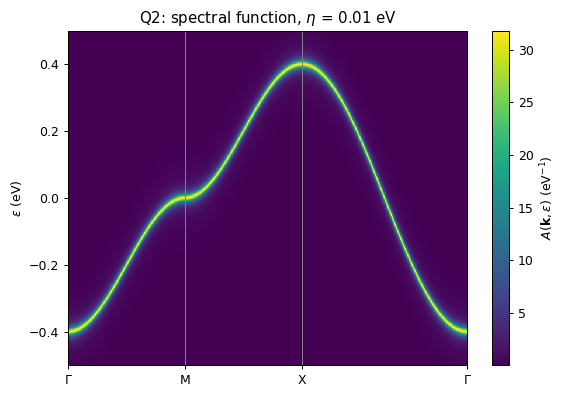

In [5]:
def G0_k(eps, eps_k, eta=eta):
    # Bare retarded Green's function in k-space.
    return 1.0 / (eps - eps_k + 1j * eta)


energies_A = np.linspace(-0.5, 0.5, 801)
A_path = -np.imag(G0_k(energies_A[:, None], eps_path[None, :])) / np.pi

fig, ax = plt.subplots(figsize=(6.5, 4.5))
pc = ax.pcolormesh(distance, energies_A, A_path, shading="auto", cmap="viridis")
fig.colorbar(pc, ax=ax, label=r"$A(\mathbf{k},\varepsilon)$ (eV$^{-1}$)")
decorate_path_axis(ax)
ax.set_ylabel(r"$\varepsilon$ (eV)")
ax.set_title(rf"Q2: spectral function, $\eta$ = {eta} eV")
fig.tight_layout(); fig.savefig("Q2_spectral_function.png", dpi=200); plt.show()

## 2.3 Check: line shape at a fixed $\mathbf{k}$

At $\Gamma$ we measure the peak height, the full width at half maximum, and the integrated weight directly from the computed $A$, and compare them with the analytic values: $1/(\pi\eta)$, $2\eta$ and question $1$.

The integral over a finite window $\pm L$ is slightly less than 1, by approximately $2\eta/(\pi L)$, because the Lorentzian tails beyond the window are cut off.

In [6]:
L = 5.0
E_fine = np.linspace(-0.4 - L, -0.4 + L, 2_000_001)
A_G = -np.imag(G0_k(E_fine, dispersion(0.0, 0.0))) / np.pi
above = E_fine[A_G >= A_G.max() / 2]
print(f"peak height : {A_G.max():.3f} eV^-1   (1/(pi eta) = {1/(np.pi*eta):.3f})")
print(f"FWHM        : {above[-1]-above[0]:.4f} eV   (2 eta = {2*eta:.4f})")
print(f"weight      : {integrate(A_G, E_fine):.5f}     (1 - 2eta/(pi L) = {1-2*eta/(np.pi*L):.5f})")

peak height : 31.831 eV^-1   (1/(pi eta) = 31.831)
FWHM        : 0.0200 eV   (2 eta = 0.0200)
weight      : 0.99873     (1 - 2eta/(pi L) = 0.99873)


## 2.4 Answer: comparison with the band structure

The spectral function reproduces the band structure of Q1 exactly. At each $\mathbf{k}$, $A(\mathbf{k},\varepsilon)$ is a single Lorentzian centred at $\varepsilon_\mathbf{k}$. So the bright ridge in the colour map traces $\varepsilon_\mathbf{k}$ along $\Gamma-M-X-\Gamma$, from $-0.4$ eV at $\Gamma$, through the flat saddle at $M$ at $0$ eV, to $+0.4$ eV at $X$.

The ridge has a finite energy width. Its full width at half maximum is $2\eta = 0.02$ eV (2.5% of the bandwidth) and its peak height is $1/(\pi\eta)\approx 32$ $eV^{-1}$, as the colour bar and the check above confirm. Each $\mathbf{k}$ carries total spectral weight exactly 1. This is the signature of non-interacting electrons: one sharp excitation per $\mathbf{k}$, with quasiparticle weight $Z=1$.

The ridge looks wider in some places, but this is a visual effect. Its width in $k$ at fixed energy is about $\eta/|\partial\varepsilon/\partial k|$. Where the band is flat along the path (near $\Gamma$, $M$ and $X$), the ridge appears broader horizontally. The energy width is the same everywhere.

The role of $\eta$. As $\eta\to0$ the ridge becomes a delta function on the band. A finite $\eta$ acts like a constant imaginary self-energy, $\Sigma = -i\eta$, i.e. a finite quasiparticle lifetime. This is the situation of tutorial sheet Q6 with $\eta = \hbar\Gamma$. In an interacting system, $\mathrm{Re}\,\Sigma$ would shift the ridge and $\mathrm{Im}\,\Sigma$ would broaden it in an energy-dependent way (lecture notes, Eq. 63). That is what ARPES measures. Here there is no self-energy, so $A$ contains no information beyond the band structure.

---
# Question 3: Density of states from the real-space Green's function

## 3.1 Why $\rho(\varepsilon) = -\frac1\pi\mathrm{Im}\,G_0(\mathbf{r}=0,\varepsilon)$

The Fourier transform to real space is
$$G_0(\mathbf{r},\varepsilon) = \frac1{N^2}\sum_\mathbf{k}e^{i\mathbf{k}\cdot\mathbf{r}}G_0(\mathbf{k},\varepsilon).$$
At $\mathbf{r}=0$ every phase factor is 1, so
$$-\frac1\pi\mathrm{Im}\,G_0(0,\varepsilon) = \frac{1}{N^2}\sum_\mathbf{k}A(\mathbf{k},\varepsilon)\ \xrightarrow{\ \eta\to0\ }\ \frac{1}{N^2}\sum_\mathbf{k}\delta(\varepsilon-\varepsilon_\mathbf{k}).$$
This counts the states per unit energy, divided by the number of sites $N^2$. It is therefore the **density of states per site (per spin)**. Since each $A$ integrates to 1, $\int\rho\,d\varepsilon = 1$.

## 3.2 Discrete Fourier transform and FFT ordering

On an $N\times N$ lattice, $\mathbf{r} = (m_x,m_y)$ with integer $m_x, m_y$, and $\mathbf{k} = \tfrac{2\pi}{N}(n_x,n_y)$. Then $\mathbf{k}\cdot\mathbf{r} = \tfrac{2\pi}{N}(n_xm_x+n_ym_y)$. This is exactly the phase used by `np.fft.ifft2`, which also includes the factor $1/N^2$:
$$\texttt{ifft2}(A)[m_x,m_y] = \frac1{N^2}\sum_{n_x,n_y}A[n_x,n_y]\,e^{2\pi i(n_xm_x+n_ym_y)/N}.$$

Ordering. `ifft2` assumes array index $n$ holds $k = 2\pi n/N$, starting with $k=0$ at index 0. Because $e^{ikr}$ is unchanged by $k\to k-2\pi$, the upper half of the array represents negative $k$. `2*np.pi*np.fft.fftfreq(N)` returns exactly this order.

Positions in the output. $\mathbf{r}=0$ is at index `[0,0]`. Negative $\mathbf{r}$ wrap around to the end of the array. `np.fft.fftshift` re-centres the array for plotting.

In [7]:
def k_grid(N, a=a):
    # N x N k-points in numpy FFT order: [0, 2pi/N, ..., pi-ish, -pi, ..., -2pi/N]
    k1d = 2.0 * np.pi * np.fft.fftfreq(N, d=a)
    return np.meshgrid(k1d, k1d, indexing="ij")     # first index = x, second = y


def G0_real_space(eps, N, eta=eta):
    # G0(r, eps) on an N x N lattice, r = 0 at index [0, 0]
    KX, KY = k_grid(N)
    return np.fft.ifft2(G0_k(eps, dispersion(KX, KY), eta))


def dos(energies, N, eta=eta):
    KX, KY = k_grid(N)
    eps_k = dispersion(KX, KY)
    rho = np.empty(len(energies))
    for i, e in enumerate(energies):
        rho[i] = -np.fft.ifft2(G0_k(e, eps_k, eta))[0, 0].imag / np.pi
    return rho


print("k-grid for N = 8 (1/a):", np.round(2*np.pi*np.fft.fftfreq(8), 3))

k-grid for N = 8 (1/a): [ 0.     0.785  1.571  2.356 -3.142 -2.356 -1.571 -0.785]


## 3.3 Exact benchmark

The $\eta\to0$, $N\to\infty$ density of states of this model has a standard closed form:
$$\rho_{\rm exact}(\varepsilon) = \frac{1}{2\pi^2t}\,K\!\left(\sqrt{1-\left(\tfrac{\varepsilon}{4t}\right)^2}\right),\qquad |\varepsilon|<4t ,$$
where $K(k)$ is the complete elliptic integral of the first kind. Two practical points:
- scipy's `ellipkm1(p)` returns $K$ for parameter $m = k^2 = 1-p$, so we pass $p = (\varepsilon/4t)^2$.
- We do not rely on the formula blindly. Below, it is checked against a histogram of $\varepsilon_\mathbf{k}$ on a $2000\times2000$ grid, and its normalisation is checked.

The fair comparison for our numerics, which use finite $\eta$, is the exact DOS **convolved with the same Lorentzian**:
$$\rho_\eta(\varepsilon) = \int\rho_{\rm exact}(\varepsilon')\,\frac{\eta/\pi}{(\varepsilon-\varepsilon')^2+\eta^2}\,d\varepsilon' .$$
This is what our $k$-sum converges to as $N\to\infty$ at fixed $\eta$.

In [8]:
def rho_exact(e):
    e = np.asarray(e, float); out = np.zeros_like(e)
    m = (np.abs(e) < 4*t) & (e != 0)
    out[m] = ellipkm1((e[m] / (4*t))**2) / (2 * np.pi**2 * t)
    return out


def rho_exact_broadened(energies, eta=eta):
    f = lambda ep: rho_exact(np.array([ep]))[0] * (eta/np.pi) / ((energies - ep)**2 + eta**2)
    lo, _ = quad_vec(f, -4*t, 0.0, epsabs=1e-9, limit=500)     # split at the log singularity
    hi, _ = quad_vec(f, 0.0, 4*t, epsabs=1e-9, limit=500)
    return lo + hi


# Check the closed form against a histogram of band energies on a fine grid
KXh, KYh = k_grid(2000)
hist, edges = np.histogram(dispersion(KXh, KYh).ravel(), bins=200, range=(-0.4, 0.4), density=True)
centres = 0.5 * (edges[1:] + edges[:-1]); away = np.abs(centres) > 0.02
print("closed form vs histogram, max relative deviation (|eps| > 0.02 eV):",
      f"{np.max(np.abs(hist[away] - rho_exact(centres[away])) / rho_exact(centres[away])):.3%}")
e_fine = np.linspace(-0.4, 0.4, 400_001)
print(f"closed form normalisation: {integrate(rho_exact(e_fine), e_fine):.4f}")

closed form vs histogram, max relative deviation (|eps| > 0.02 eV): 0.613%
closed form normalisation: 1.0000


## 3.4 DOS for $N = 256$, with checks

G0(r=0) via FFT : (2.440167-4.129056j)
G0(r=0) k-mean  : (2.440167-4.129056j)
integral of rho over [-0.6, 0.6] eV: 0.9878
max |rho_N - rho_eta| = 1.9e-06 eV^-1
rho(0)            = 2.571 eV^-1,  ln(16t/eta)/(2 pi^2 t) = 2.571
band-edge step    = 1/(4 pi t) = 0.796 eV^-1


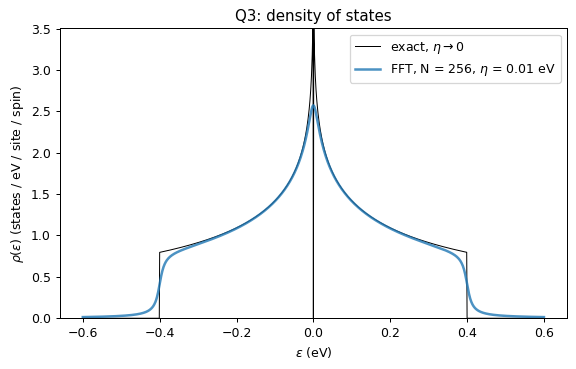

In [9]:
N_dos = 256
energies_dos = np.linspace(-0.6, 0.6, 1201)
rho_dos = dos(energies_dos, N_dos)
rho_ref = rho_exact_broadened(energies_dos)

# Check 1: FFT value at r = 0 equals the plain k-average
KX, KY = k_grid(N_dos)
print("G0(r=0) via FFT :", np.round(G0_real_space(0.123, N_dos)[0, 0], 6))
print("G0(r=0) k-mean  :", np.round(np.mean(G0_k(0.123, dispersion(KX, KY))), 6))
# Check 2: normalisation (deficit = Lorentzian tails outside the window)
print(f"integral of rho over [-0.6, 0.6] eV: {integrate(rho_dos, energies_dos):.4f}")
# Check 3: agreement with exact broadened DOS
print(f"max |rho_N - rho_eta| = {np.max(np.abs(rho_dos - rho_ref)):.1e} eV^-1")
# Key numbers used in the discussion
print(f"rho(0)            = {rho_dos[600]:.3f} eV^-1,  ln(16t/eta)/(2 pi^2 t) = {np.log(16*t/eta)/(2*np.pi**2*t):.3f}")
print(f"band-edge step    = 1/(4 pi t) = {1/(4*np.pi*t):.3f} eV^-1")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(energies_dos, rho_exact(energies_dos), "k-", lw=0.8, label=r"exact, $\eta\to0$")
ax.plot(energies_dos, rho_dos, lw=2, alpha=0.8, label=rf"FFT, N = {N_dos}, $\eta$ = {eta} eV")
ax.set_ylim(0, 3.5)
ax.set_xlabel(r"$\varepsilon$ (eV)"); ax.set_ylabel(r"$\rho(\varepsilon)$ (states / eV / site / spin)")
ax.set_title("Q3: density of states"); ax.legend()
fig.tight_layout(); fig.savefig("Q3_dos.png", dpi=200); plt.show()

## 3.5 Dependence on the number of $k$-points

The cell below repeats the calculation for several grid sizes and reports the largest deviation from the converged result $\rho_\eta$.

 N   max|rho_N - rho_eta| (eV^-1)   relative to peak
   8       4.5634                     177.51%
  16       1.7271                      67.18%
  32       0.4485                      17.45%
  64       0.0576                       2.24%


 128       0.0016                       0.06%


 256       0.0000                       0.00%


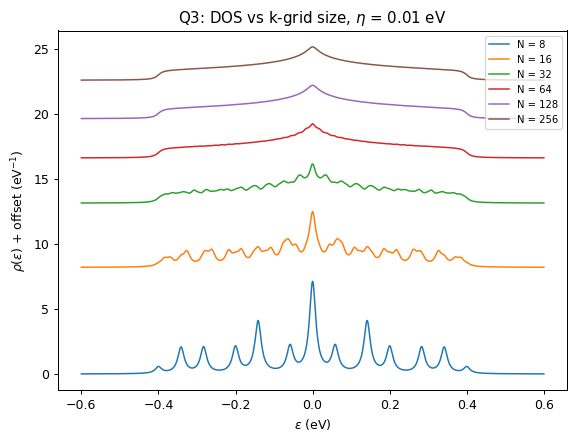

N =   8: 14 of 64 k-points have eps = 0 exactly  ->  peak ~ 6.96 eV^-1
N =  16: 30 of 256 k-points have eps = 0 exactly  ->  peak ~ 3.73 eV^-1
N =  32: 62 of 1024 k-points have eps = 0 exactly  ->  peak ~ 1.93 eV^-1


In [10]:
N_list = [8, 16, 32, 64, 128, 256]
fig, ax = plt.subplots(figsize=(6.5, 5))
offset = 0.0
print(" N   max|rho_N - rho_eta| (eV^-1)   relative to peak")
for N in N_list:
    r = dos(energies_dos, N)
    dev = np.max(np.abs(r - rho_ref))
    print(f"{N:4d}   {dev:10.4f}                    {dev/rho_ref.max():8.2%}")
    ax.plot(energies_dos, r + offset, lw=1.2, label=f"N = {N}")
    offset += 1.15 * r.max()
ax.set_xlabel(r"$\varepsilon$ (eV)"); ax.set_ylabel(r"$\rho(\varepsilon)$ + offset (eV$^{-1}$)")
ax.set_title(rf"Q3: DOS vs k-grid size, $\eta$ = {eta} eV"); ax.legend(fontsize=8, loc="upper right")
fig.tight_layout(); fig.savefig("Q3_dos_convergence.png", dpi=200); plt.show()

# Degeneracy at eps = 0 on small grids (explains the spurious central peak)
for N in [8, 16, 32]:
    KX, KY = k_grid(N); n0 = np.sum(np.abs(dispersion(KX, KY)) < 1e-12)
    print(f"N = {N:3d}: {n0} of {N*N} k-points have eps = 0 exactly  ->  peak ~ {n0/N**2/(np.pi*eta):.2f} eV^-1")

## 3.6 Answers

### (a) How does the number of $k$-points influence the result?

**What the code actually computes.** On an $N\times N$ grid, the computed $\rho(\varepsilon)$ is a sum of $N^2$ Lorentzians of width $\eta$, one centred on each discrete eigenvalue $\varepsilon_\mathbf{k}$. In other words, it is the exact DOS of a *finite* $N\times N$ periodic lattice, broadened by $\eta$.

**When does it become smooth?** It approaches the infinite-lattice result $\rho_\eta$ once the Lorentzians from neighbouring $k$-points overlap. That requires the energy step between neighbouring $k$-points to be smaller than $\eta$:
$$\Delta\varepsilon \approx |\nabla_\mathbf{k}\varepsilon|\,\frac{2\pi}{Na}\lesssim\eta .$$
Taking a typical gradient $|\nabla_\mathbf{k}\varepsilon|\approx 2ta$ gives
$$N\gtrsim\frac{4\pi t}{\eta}\approx 126 .$$

**This matches the numbers.** The maximum deviation is 17% of the peak at $N=32$, 2% at $N=64$, 0.06% at $N=128$, and below $10^{-4}$ at $N=256$. Once $N$ passes this threshold, the error falls off exponentially. This is expected: the $k$-sum is a trapezoidal rule applied to a smooth periodic function, which converges exponentially.

**$N$ and $\eta$ must be chosen together.** Halving $\eta$ requires doubling $N$, and the cost per energy grows as $N^2\log N$.

### (b) What happens with too few $k$-points?

The DOS breaks up into **separate spikes** at the few discrete energies of a small cluster. These spikes are artefacts of the grid, not features of the band.

Example: for $N=8$, 14 of the 64 grid points lie exactly on the half-filling square $|k_x|+|k_y|=\pi$. In general this is $2N-2$ of $N^2$ points. All 14 contribute a Lorentzian at $\varepsilon=0$, giving a spurious peak of height $\approx (14/64)/(\pi\eta)\approx 7$ eV$^{-1}$, compared with the converged 2.57 eV$^{-1}$.

Reducing $\eta$ at fixed $N$ has the same effect: once $\eta$ is smaller than the level spacing, the individual levels show up as spikes.

### (c) Relation of DOS features to the band structure

**1. Band edges at $\varepsilon=\pm4t=\pm0.4$ eV.** These correspond to the band bottom at $\Gamma$ and the band top at $X$. The DOS is zero outside $[-4t,4t]$ and jumps *discontinuously* at each edge to
$$\rho = \frac{1}{4\pi t} = 0.80\ \text{eV}^{-1}.$$
The reason is that near $\Gamma$ (and near $X$) the band is an isotropic 2D parabola with $m^* = \hbar^2/(2ta^2)$. A 2D parabolic band has a constant DOS (tutorial sheet, Q2): $m^*/(2\pi\hbar^2)$ per unit area per spin. Multiplying by the area per site, $a^2$, gives
$$\frac{a^2m^*}{2\pi\hbar^2} = \frac{1}{4\pi t}.$$
With finite $\eta$, the steps are rounded over an energy range of about $\eta$.

**2. Logarithmic peak at $\varepsilon=0$.** This is a **van Hove singularity** from the saddle points at $M = (\pi,0)$ and $(0,\pi)$, which appear as the flat inflection in Q1. Near one saddle, $\varepsilon\approx t(p_y^2-p_x^2)$ with $a=1$.

*Step 1.* Write the DOS contribution from one saddle as a 2D integral (per site, per spin):
$$\rho_{\rm saddle}(\varepsilon) = \frac{1}{(2\pi)^2}\int dp_x\,dp_y\;\delta\big(\varepsilon - t(p_y^2-p_x^2)\big),$$
with $|p_x|, |p_y|$ below some cutoff $\Lambda$ of order 1, beyond which the quadratic approximation fails.

*Step 2.* Do the $p_y$ integral first, at fixed $p_x$ (take $\varepsilon>0$). The delta function fires when $p_y = \pm\sqrt{p_x^2+\varepsilon/t}$. At each root, $\left|\partial_{p_y}\big[t(p_y^2-p_x^2)\big]\right| = 2t|p_y|$. Two roots, each contributing $1/(2t|p_y|)$, give
$$\int dp_y\,\delta(\ldots) = \frac{1}{t\sqrt{p_x^2+\varepsilon/t}}.$$

*Step 3.* Do the $p_x$ integral. With $\int_{-\Lambda}^{\Lambda}\frac{dx}{\sqrt{x^2+c^2}}\approx 2\ln(2\Lambda/c)$ for $c\ll\Lambda$, and $c=\sqrt{\varepsilon/t}$:
$$\rho_{\rm saddle}\approx\frac{1}{4\pi^2t}\cdot 2\ln\frac{2\Lambda}{\sqrt{\varepsilon/t}} = \frac{1}{4\pi^2t}\ln\frac{4\Lambda^2t}{\varepsilon}.$$
The same holds for $\varepsilon<0$ with $|\varepsilon|$.

*Step 4.* There are two inequivalent saddles, so
$$\rho\approx\frac{1}{2\pi^2t}\ln\frac{C\,t}{|\varepsilon|}.$$
The constant $C=16$ is fixed by the exact result. The cutoff argument only gives it to order 1.

The divergence is integrable. Finite $\eta$ caps it: averaging $\ln|\varepsilon'|$ over a Lorentzian of width $\eta$ gives $\ln\eta$, so
$$\rho_\eta(0) = \frac{1}{2\pi^2t}\ln\frac{16t}{\eta} = 2.57\ \text{eV}^{-1}.$$
This matches the computed value printed in 3.4.

**3. Symmetry about $\varepsilon=0$.** This follows from particle–hole symmetry, $\varepsilon_{\mathbf{k}+\mathbf{Q}}=-\varepsilon_\mathbf{k}$. Half of the states lie below zero, so $\varepsilon=0$ corresponds to half filling.

**4. Total weight.** The DOS integrates to one state per site per spin, as it must for a single band. Numerically we get 0.99 over the plotted window; the deficit is the Lorentzian tails outside it.

---
# Question 4: Quasi-particle interference (QPI)

## 4.1 Where the sheet's formula comes from (background)

Add a single-site potential, $H = H_0 + V|0\rangle\langle0|$. Then $G^{-1} = G_0^{-1} - \hat V$. Multiplying this on the left by $G_0$ and on the right by $G$ gives $G = G_0 + G_0\hat VG$. In site components:
$$G(\mathbf{r},\mathbf{r}') = G_0(\mathbf{r},\mathbf{r}') + G_0(\mathbf{r},0)\,V\,G(0,\mathbf{r}').$$
Setting $\mathbf{r}=0$:
$$G(0,\mathbf{r}') = \frac{G_0(0,\mathbf{r}')}{1 - VG_0(0,0)}.$$
Substituting back:
$$G(\mathbf{r},\mathbf{r}') = G_0(\mathbf{r},\mathbf{r}') + G_0(\mathbf{r},0)\,T\,G_0(0,\mathbf{r}'),\qquad T=\frac{V}{1-VG_0(0,0)} .$$

The clean system is translation invariant, so $G_0(\mathbf{r},\mathbf{r}') = G_0(\mathbf{r}-\mathbf{r}')$. Setting $\mathbf{r}'=\mathbf{r}$ gives the sheet's expression:
$$G(\mathbf{r},\mathbf{r};\varepsilon) = G_0(0) + G_0(\mathbf{r})\,T\,G_0(-\mathbf{r}).$$

This **$T$-matrix** result is exact to all orders in $V$. In the Born limit, $|VG_0(0)|\ll1$, it reduces to $T\approx V$.

The LDOS change caused by the defect is
$$\delta\rho(\mathbf{r},\varepsilon) = \rho(\mathbf{r},\varepsilon) - \rho_0(\varepsilon) = -\frac1\pi\mathrm{Im}\big[T\,G_0(\mathbf{r})G_0(-\mathbf{r})\big].$$

## 4.2 What the Fourier transform measures (key physics for the discussion)

Take the Fourier transform of $G_0(\mathbf{r})G_0(-\mathbf{r})$. Insert $G_0(\mathbf{r}) = \frac1{N^2}\sum_\mathbf{k}e^{i\mathbf{k}\cdot\mathbf{r}}G_0(\mathbf{k})$ and use $\sum_\mathbf{r}e^{i(\mathbf{k}-\mathbf{k}'-\mathbf{q})\cdot\mathbf{r}} = N^2\delta_{\mathbf{k}',\mathbf{k}-\mathbf{q}}$:
$$\sum_\mathbf{r}e^{-i\mathbf{q}\cdot\mathbf{r}}G_0(\mathbf{r})G_0(-\mathbf{r}) = \frac1{N^2}\sum_\mathbf{k}G_0(\mathbf{k},\varepsilon)\,G_0(\mathbf{k}-\mathbf{q},\varepsilon)\equiv\Lambda(\mathbf{q},\varepsilon).$$

Using $\Lambda(-\mathbf{q}) = \Lambda(\mathbf{q})$ (shift $\mathbf{k}\to\mathbf{k}+\mathbf{q}$ in the sum), this gives
$$\delta\rho(\mathbf{q},\varepsilon) = -\frac1\pi\mathrm{Im}\big[T\,\Lambda(\mathbf{q},\varepsilon)\big].$$

**Where $\Lambda$ is large.** Each term in $\Lambda$ is large only when **both** $\mathbf{k}$ and $\mathbf{k}-\mathbf{q}$ lie within about $\eta$ of the constant-energy contour (CEC) $\varepsilon_\mathbf{k}=\varepsilon$. $\Lambda$ becomes singular at those $\mathbf{q}$ for which the contour and its copy shifted by $\mathbf{q}$ touch tangentially. Those are the $\mathbf{q}$ that **connect two points of the CEC with parallel tangents**, i.e. with parallel or antiparallel velocities.

Backscattering, $\mathbf{k}\to-\mathbf{k}$, is always such a process here, because $\varepsilon_{-\mathbf{k}}=\varepsilon_\mathbf{k}$. It gives $\mathbf{q}=2\mathbf{k}$. Hence:

> **The QPI pattern at energy $\varepsilon$ is the constant-energy contour scaled by a factor 2.**

**Folding.** $\rho$ is only defined on lattice sites, so $\mathbf{q}$ and $\mathbf{q}+\mathbf{G}$ cannot be distinguished, where $\mathbf{G}$ is any reciprocal lattice vector ($2\pi/a$ times integers). Parts of the $2\mathbf{k}$ contour that fall outside the first Brillouin zone therefore reappear folded back inside it. In practice, $\mathbf{q}$ lies on the folded contour if $\varepsilon(\mathbf{q}/2+\pi\mathbf{m})=\varepsilon$ for some $\mathbf{m}\in\{0,1\}^2$. This is how the overlay in the plots is drawn.

**Real-space picture.** Far from the defect, $G_0(\mathbf{r})$ is dominated by the CEC point(s) whose group velocity points along $\mathbf{r}$ (stationary phase). In 2D this gives
$$G_0(\mathbf{r})\sim e^{i\mathbf{k}_r\cdot\mathbf{r}}/\sqrt{r}.$$
Squaring it, $\delta\rho\sim\mathrm{Im}[T\,e^{2i\mathbf{k}_r\cdot\mathbf{r}}]/r$. These are **Friedel-like standing waves** of wavevector $2\mathbf{k}_r$, decaying as $1/r$. That is the decay of the energy-resolved LDOS, which is what an STM $dI/dV$ map measures. The total charge-density Friedel oscillation in 2D decays faster, as $1/r^2$.

The finite $\eta$ adds damping, $e^{-r/\ell_\eta}$, with $\ell_\eta = |\nabla_\mathbf{k}\varepsilon|/(2\eta)$.

The amplitude also scales as (curvature of the CEC)$^{-1/2}$. So flat parts of the contour **focus** the scattered waves into beams.

In [11]:
N_qpi  = 128      # lattice / k-grid size, as suggested on the sheet
V      = 0.2      # defect potential (eV) = 2t
eps_F  = -0.1     # chosen Fermi level (eV), see the introduction


def minus_r(arr):
    # arr evaluated at -r: index (-m) mod N in each direction
    return np.roll(np.flip(arr, axis=(0, 1)), shift=1, axis=(0, 1))


def ldos_with_defect(eps, N=N_qpi, V=V, eta=eta):
    # Returns rho(r, eps) with the defect at r = 0 (index [0, 0]), and the clean rho_0(eps)
    G0r = G0_real_space(eps, N, eta)
    G00 = G0r[0, 0]
    T   = V / (1.0 - V * G00)
    G   = G00 + G0r * T * minus_r(G0r)
    return -G.imag / np.pi, -G00.imag / np.pi


# Basic checks
G0r_test = G0_real_space(0.05, N_qpi)
print("inversion symmetry, max |G0(r) - G0(-r)| =", f"{np.max(np.abs(G0r_test - minus_r(G0r_test))):.1e}")
for e in [-0.35, -0.2, -0.1, 0.0, 0.1, 0.2]:
    g = G0_real_space(e, N_qpi)[0, 0]
    print(f"eps = {e:+.2f} eV: G0(0) = {g.real:+.3f}{g.imag:+.3f}i eV^-1,  |V G0(0)| = {abs(V*g):.2f}")

inversion symmetry, max |G0(r) - G0(-r)| = 4.7e-16
eps = -0.35 eV: G0(0) = -3.427-2.537i eV^-1,  |V G0(0)| = 0.85
eps = -0.20 eV: G0(0) = -2.612-3.409i eV^-1,  |V G0(0)| = 0.86
eps = -0.10 eV: G0(0) = -2.389-4.440i eV^-1,  |V G0(0)| = 1.01
eps = +0.00 eV: G0(0) = +0.000-8.082i eV^-1,  |V G0(0)| = 1.62
eps = +0.10 eV: G0(0) = +2.389-4.440i eV^-1,  |V G0(0)| = 1.01
eps = +0.20 eV: G0(0) = +2.612-3.409i eV^-1,  |V G0(0)| = 0.86


The printout shows $|VG_0(0)|\approx 0.9$–$1.6$ at these energies. So $V=0.2$ eV is **not** in the Born limit, and the full $T$-matrix is needed.

## 4.3 Plotting tools

Each figure has four panels:
- **(a)** the constant-energy contour $\varepsilon_\mathbf{k}=\varepsilon$ in $k$-space (the Fermi surface, when $\varepsilon=\varepsilon_F$);
- **(b)** the real-space LDOS $\rho(\mathbf{r},\varepsilon)$. The colour scale is centred on the clean value $\rho_0(\varepsilon)$, so red means enhanced and blue means suppressed;
- **(c)** $|\mathcal{F}\rho(\mathbf{q})|$;
- **(d)** the same as (c), with the folded $2\mathbf{k}$ contour from 4.2 overlaid as dashed cyan lines.

**Two technical choices in the transform.**
1. We subtract the spatial mean before transforming. Otherwise the $\mathbf{q}=0$ component, which is just the average LDOS and is about $N^2$ times larger than everything else, sets the colour scale.
2. The colour scales are clipped at a high percentile, because the LDOS on and next to the defect site is far larger than the oscillations further out.

In [12]:
def _contour_if_present(ax, x, Z, level, **kw):
    if Z.min() < level < Z.max():
        ax.contour(x, x, Z.T, levels=[level], **kw)


def draw_cec(ax, eps, n=401):
    k = np.linspace(-np.pi, np.pi, n); KX, KY = np.meshgrid(k, k, indexing="ij")
    _contour_if_present(ax, k/np.pi, dispersion(KX, KY), eps, colors="C3", linewidths=1.5, linestyles="solid")
    ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], "k-", lw=0.8)
    for lab, (x, y) in {r"$\Gamma$": (0, 0), "M": (1, 0), "X": (1, 1)}.items():
        ax.plot(x, y, "ko", ms=3); ax.annotate(lab, (x, y), xytext=(3, 3), textcoords="offset points")
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05); ax.set_aspect("equal")
    ax.set_xlabel(r"$k_x$ ($\pi/a$)"); ax.set_ylabel(r"$k_y$ ($\pi/a$)")


def draw_folded_2k(ax, eps, n=401):
    # q is on the folded 2k contour if eps(q/2 + pi*m) = eps for some m in {0,1}^2
    q = np.linspace(-np.pi, np.pi, n); QX, QY = np.meshgrid(q, q, indexing="ij")
    for mx, my in [(0, 0), (1, 0), (0, 1), (1, 1)]:
        _contour_if_present(ax, q/np.pi, dispersion(QX/2 + np.pi*mx, QY/2 + np.pi*my), eps,
                            colors="cyan", linewidths=0.9, linestyles="--")


def fourier_map(rho):
    N = rho.shape[0]
    F = np.fft.fftshift(np.abs(np.fft.fft2(rho - rho.mean())))
    q = np.fft.fftshift(2.0 * np.fft.fftfreq(N))              # units of pi/a
    return F, q


def plot_qpi(eps, N=N_qpi, V=V, eta=eta, half_window=25, save=None):
    rho, rho0 = ldos_with_defect(eps, N, V, eta)
    x = np.arange(-N // 2, N // 2); sel = np.abs(x) <= half_window
    win = np.fft.fftshift(rho)[np.ix_(sel, sel)]
    F, q = fourier_map(rho); dq = q[1] - q[0]
    ext_q = [q[0] - dq/2, q[-1] + dq/2, q[0] - dq/2, q[-1] + dq/2]

    fig, ax = plt.subplots(2, 2, figsize=(10.5, 9.5))
    draw_cec(ax[0, 0], eps); ax[0, 0].set_title(rf"(a) contour $\varepsilon_\mathbf{{k}}$ = {eps:+.3f} eV")

    dev = np.percentile(np.abs(win - rho0), 99)
    im = ax[0, 1].imshow(win.T, origin="lower", cmap="RdBu_r", vmin=rho0 - dev, vmax=rho0 + dev,
                         extent=[-half_window - .5, half_window + .5, -half_window - .5, half_window + .5])
    fig.colorbar(im, ax=ax[0, 1], label=r"$\rho(\mathbf{r},\varepsilon)$ (eV$^{-1}$)")
    ax[0, 1].set_xlabel(r"$x$ ($a$)"); ax[0, 1].set_ylabel(r"$y$ ($a$)")
    ax[0, 1].set_title(rf"(b) LDOS, $\rho_0$ = {rho0:.3f} eV$^{{-1}}$")

    for k, axx in enumerate([ax[1, 0], ax[1, 1]]):
        im = axx.imshow(F.T, origin="lower", cmap="magma", extent=ext_q, vmin=0, vmax=np.percentile(F, 99.5))
        axx.set_xlabel(r"$q_x$ ($\pi/a$)"); axx.set_ylabel(r"$q_y$ ($\pi/a$)")
    fig.colorbar(im, ax=ax[1, 1], label=r"$|\mathcal{F}\rho|$ (arb.)")
    draw_folded_2k(ax[1, 1], eps)
    ax[1, 0].set_title(r"(c) $|\mathcal{F}\rho(\mathbf{q})|$")
    ax[1, 1].set_title(r"(d) same, with folded $2\mathbf{k}$ contour")

    fig.suptitle(rf"Q4: $\varepsilon$ = {eps:+.3f} eV,  N = {N},  V = {V} eV,  $\eta$ = {eta} eV")
    fig.tight_layout()
    if save: fig.savefig(save, dpi=200)
    plt.show()

## 4.4 Results at the Fermi level, $\varepsilon_F = -0.1$ eV

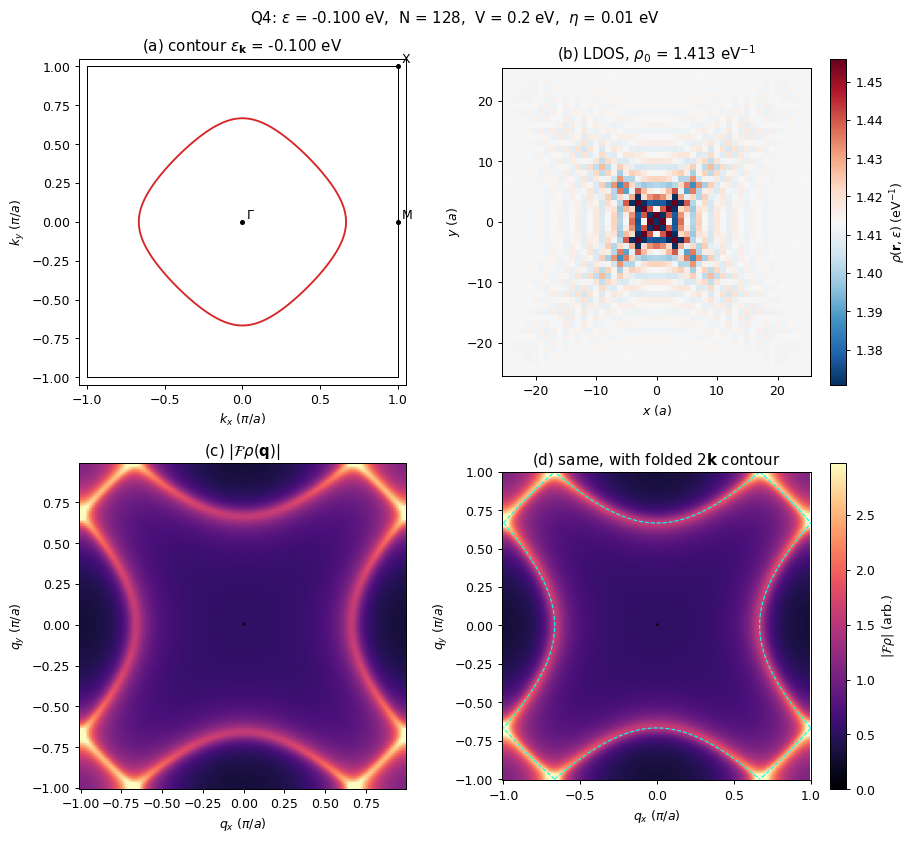

k_F along axis      = 0.667 pi/a ;  2k_F = 1.333 -> folded 0.667 pi/a
k_F on diagonal     = (0.420, 0.420) pi/a ;  2k_F = (0.839, 0.839) pi/a (no folding)
real-space period along x        = 3.00 sites
real-space period along diagonal = 6.22 diagonal steps
decay length l_eta along x       = 8.7 a
decay length l_eta along diagonal= 13.7 a
measured period along x        = 3.00 sites
measured period along diagonal = 6.21 diagonal steps


In [13]:
plot_qpi(eps_F, save="Q4_qpi_fermi_level.png")

# Numbers quoted in the discussion
kF_ax = np.arccos(-eps_F/(2*t) - 1)          # Fermi wavevector along k_x (on Gamma-M)
kF_d  = np.arccos(-eps_F/(4*t))              # k_x = k_y component on the diagonal
fold  = lambda q: (q + np.pi) % (2*np.pi) - np.pi
print(f"k_F along axis      = {kF_ax/np.pi:.3f} pi/a ;  2k_F = {2*kF_ax/np.pi:.3f} -> folded {abs(fold(2*kF_ax))/np.pi:.3f} pi/a")
print(f"k_F on diagonal     = ({kF_d/np.pi:.3f}, {kF_d/np.pi:.3f}) pi/a ;  2k_F = ({2*kF_d/np.pi:.3f}, {2*kF_d/np.pi:.3f}) pi/a (no folding)")
print(f"real-space period along x        = {2*np.pi/abs(fold(2*kF_ax)):.2f} sites")
print(f"real-space period along diagonal = {2*np.pi/abs(fold(4*kF_d)):.2f} diagonal steps")
print(f"decay length l_eta along x       = {2*t*np.sin(kF_ax)/(2*eta):.1f} a")
print(f"decay length l_eta along diagonal= {2*np.sqrt(2)*t*np.sin(kF_d)/(2*eta):.1f} a")

# Check the periods directly: dominant frequency of line profiles (N = 256, sites 3..40 from the defect)
rho256, _ = ldos_with_defect(eps_F, N=256)
def dominant_period(p):
    p = (p - p.mean()) * np.hanning(len(p)); F = np.abs(np.fft.rfft(p, 4096)); f = np.fft.rfftfreq(4096)
    return 1 / f[np.argmax(F[1:]) + 1]
print(f"measured period along x        = {dominant_period(rho256[3:41, 0]):.2f} sites")
print(f"measured period along diagonal = {dominant_period(np.array([rho256[s, s] for s in range(3, 41)])):.2f} diagonal steps")

### Answer: discussion at $\varepsilon_F$

**Fermi surface, panel (a).** At $\varepsilon_F=-0.1$ eV the Fermi surface is a closed, electron-like contour around $\Gamma$. It has the rounded-square shape anticipated in Q1, bulging towards $M$. Its size is $k_F=2/3\,\pi/a$ along the axes and $(0.42,0.42)\pi/a$ along the diagonals.

**Real space, panel (b).** The defect produces standing-wave modulations of the LDOS: quasiparticle interference between waves incident on the defect and waves scattered by it. Their features:
- They have the **four-fold ($C_{4v}$) symmetry** of the lattice. The wavefronts are not circles, because the Fermi surface is not a circle.
- Along the axes the modulation has wavevector $2k_F = 4\pi/3a$. On a lattice this is indistinguishable from $2\pi/3a$, so the modulation repeats every **3 sites**. Along the diagonal, the period is $\approx 6.2$ diagonal steps. (Both periods are confirmed by the line-profile analysis printed above.)
- The amplitude is largest next to the defect. It decays as $1/r$ times $e^{-r/\ell_\eta}$, with $\ell_\eta\approx 9a$ (axes) to $14a$ (diagonals). So the modulations are visible out to $\sim15$–$20$ sites. Since $\ell_\eta \ll N/2 = 64$, the periodic images of the defect created by the FFT are negligible (checked in 4.8).
- The sites immediately next to the defect show the largest changes. These encode the local, short-range response to $V$, rather than long-wavelength interference.

**Fourier transform, panels (c) and (d), and the relation to the Fermi surface.** $|\mathcal{F}\rho|$ is concentrated on sharp closed curves. These lie **exactly on the Fermi surface of Q1 scaled by a factor 2 and folded back into the first Brillouin zone** (dashed cyan in panel d).

- Along the diagonals, $2\mathbf{k}_F = (0.84,0.84)\pi/a$ is inside the zone, so it appears directly.
- Along the axes, $2k_F = 1.33\pi/a$ lies outside the zone. It folds back to $\pm0.67\pi/a$. This is why the pattern consists of arcs centred on the zone-edge midpoints $(\pm\pi,0)$ and $(0,\pm\pi)$, rather than a single closed loop around $\Gamma$.

This is the backscattering ($\mathbf{q}=2\mathbf{k}$) mechanism of 4.2. It is why QPI imaging by STM measures the Fermi surface. The anisotropy of the Fermi surface is directly visible in the QPI contour.

The diffuse background in panel (c) comes from the large LDOS change on and next to the defect site. Being short-ranged in real space, it is broad in $\mathbf{q}$.

## 4.5 A series of energies across the band

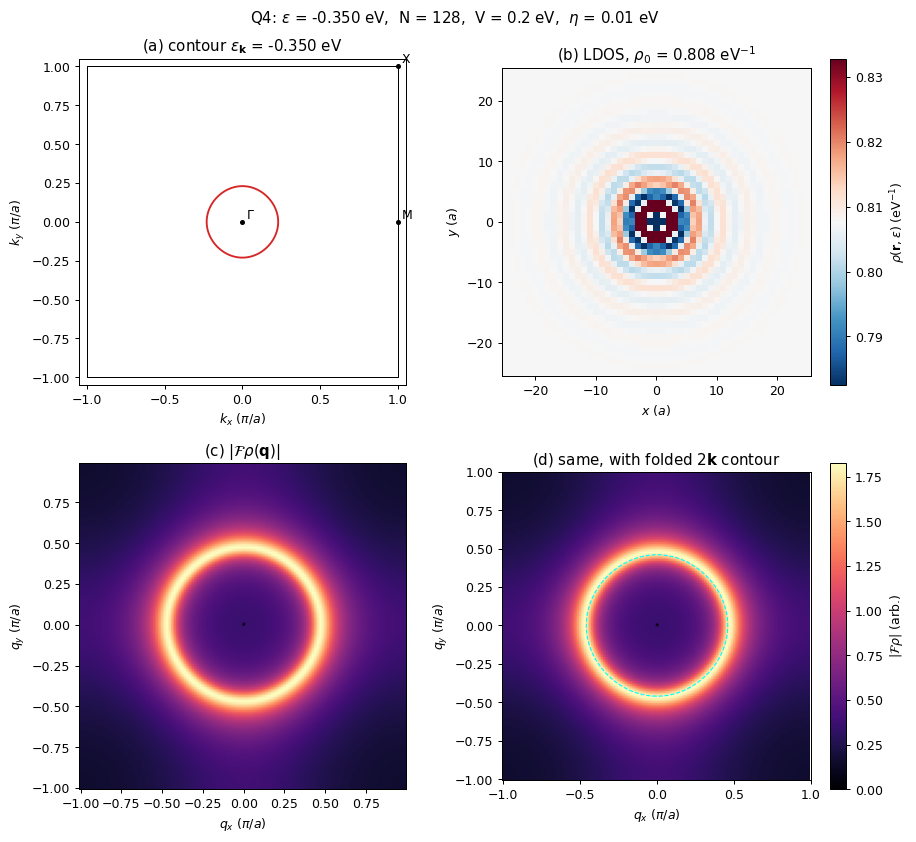

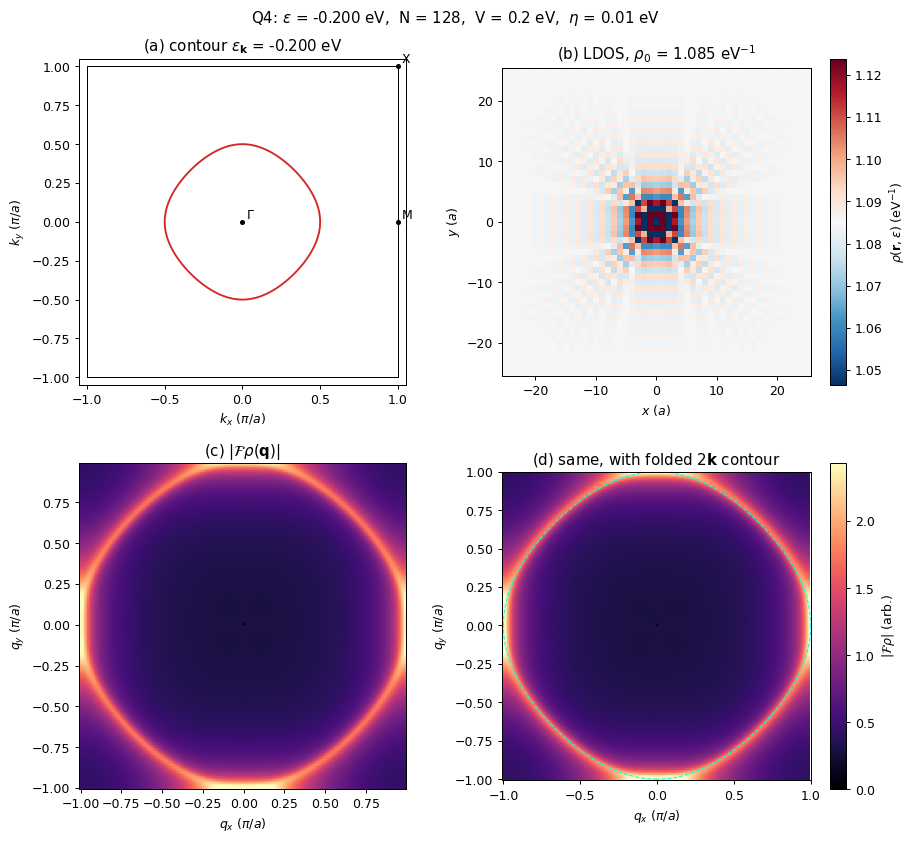

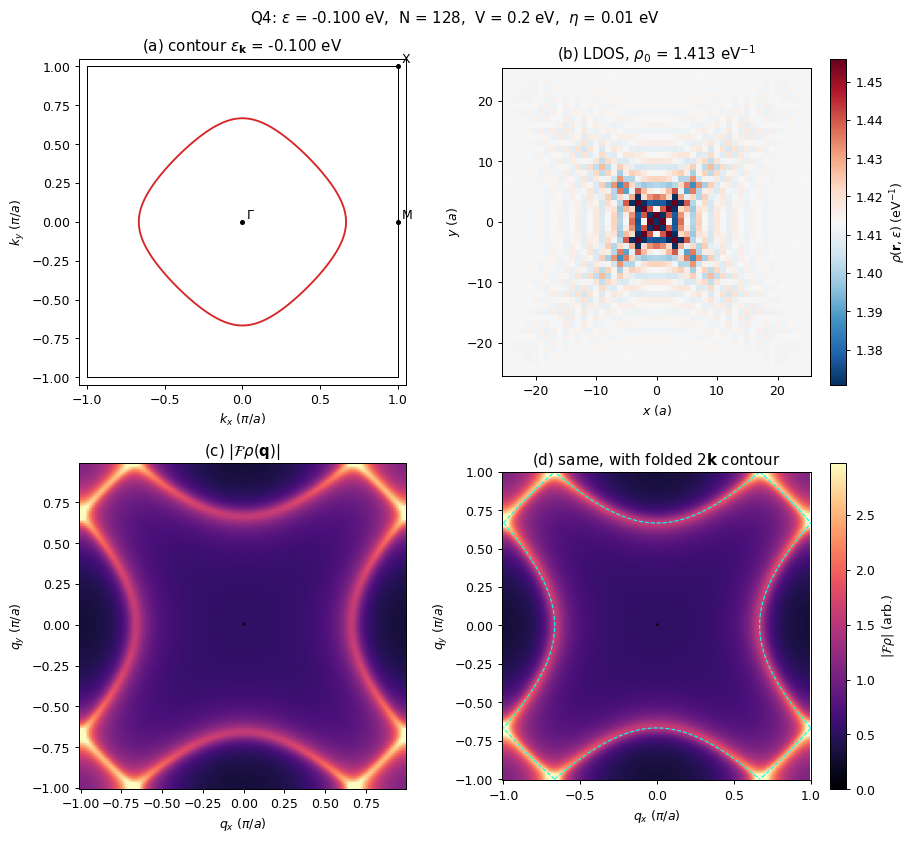

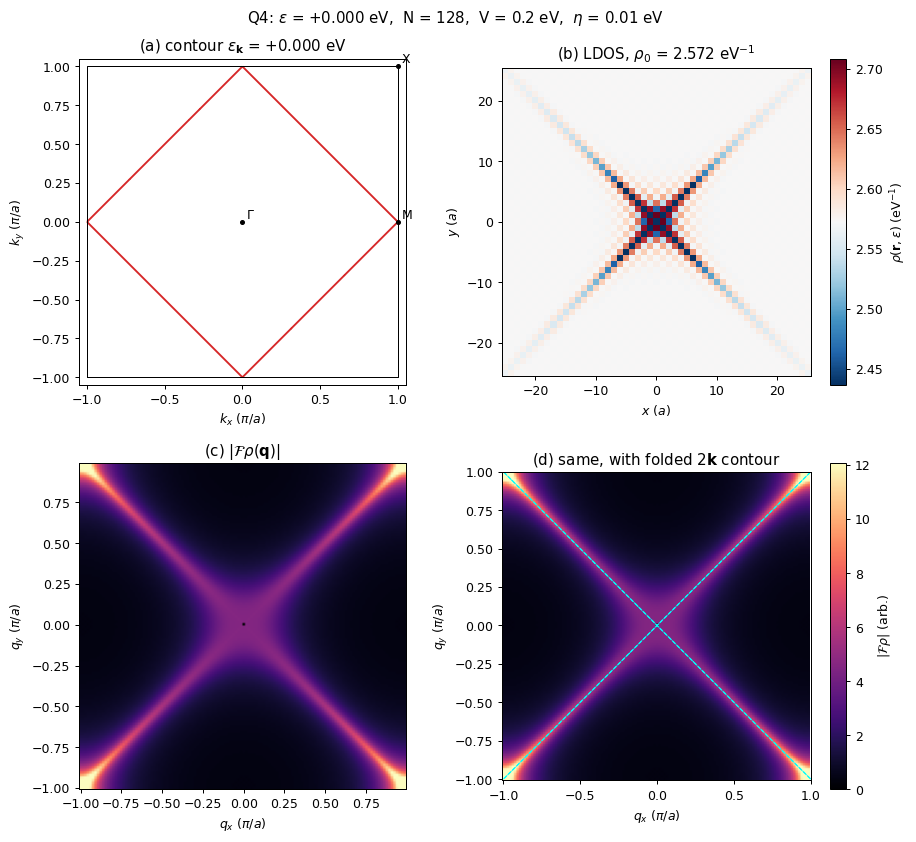

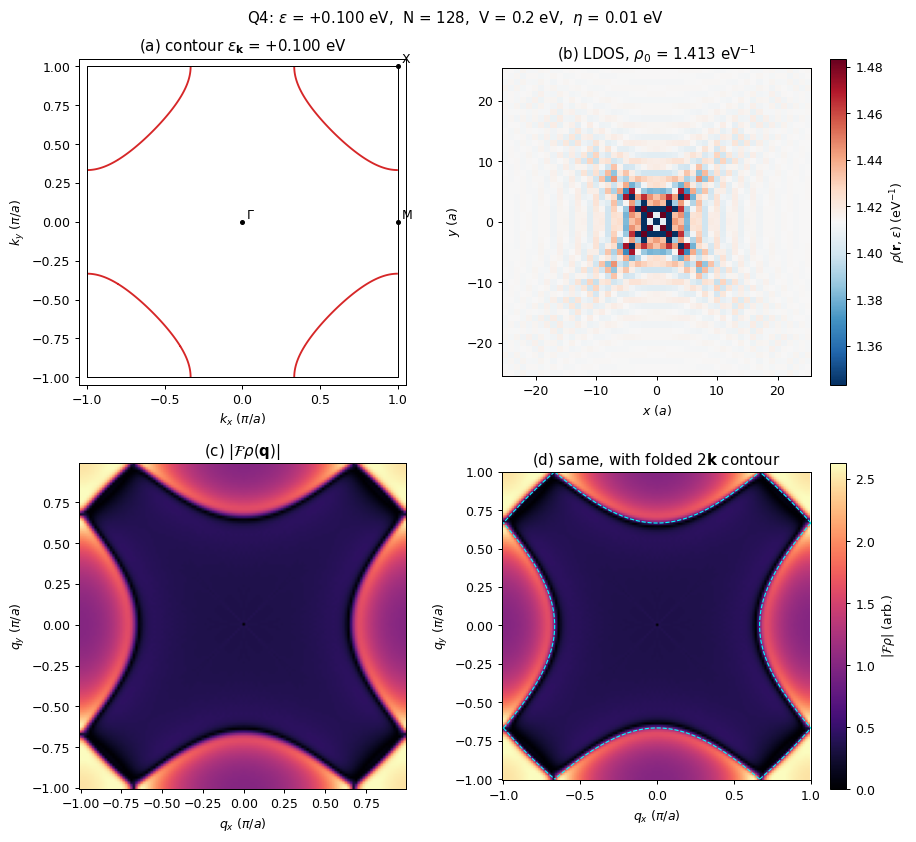

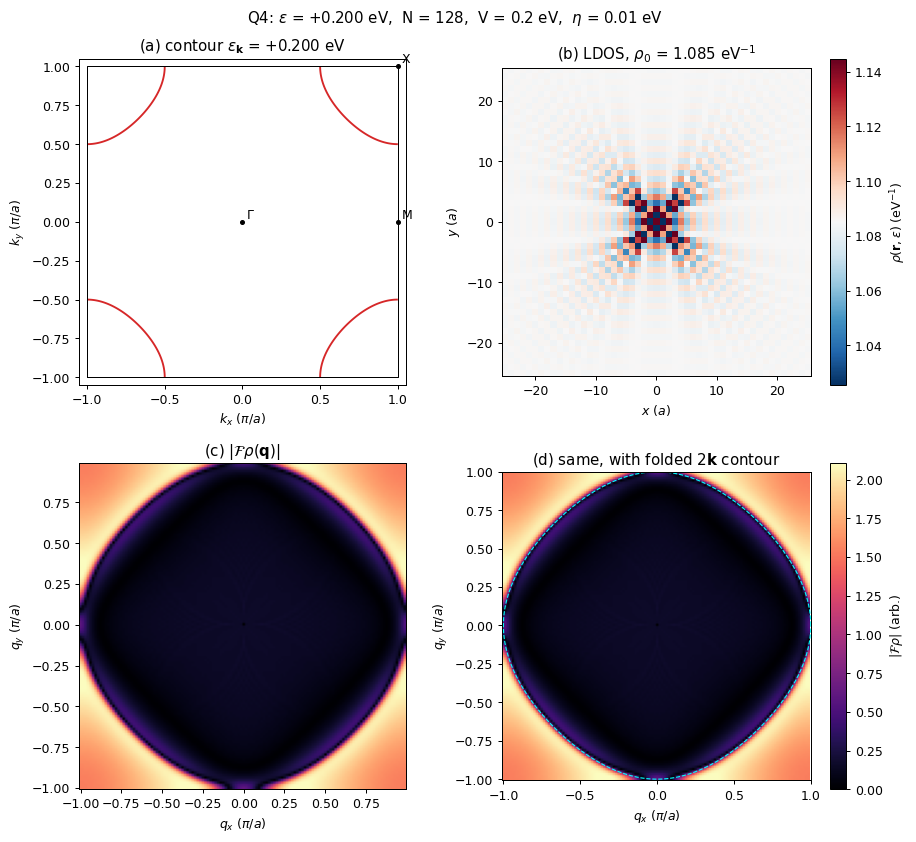

In [14]:
energies_qpi = [-0.35, -0.2, -0.1, 0.0, 0.1, 0.2]
for i, e in enumerate(energies_qpi):
    plot_qpi(e, save=f"Q4_qpi_{i}_{e:+.2f}eV.png")

## 4.6 QPI dispersion: an energy–momentum cut

A compact way to relate QPI to the band structure is to plot $|\mathcal{F}\rho(q_x, q_y=0)|$ against energy. Each energy row is normalised to its own maximum, so that weak rows are still visible.

The backscattering prediction (dashed) uses the CEC point on the $q_x$ axis:
- for $\varepsilon<0$, $\cos k = -1-\varepsilon/2t$ (point on $\Gamma\to M$);
- for $\varepsilon>0$, $\cos k = 1-\varepsilon/2t$ (point on $M\to X$, i.e. the hole pocket around $X$);

with $q = 2k$, folded into the first zone.

The dark vertical line at $q_x=0$ is simply the subtracted mean.

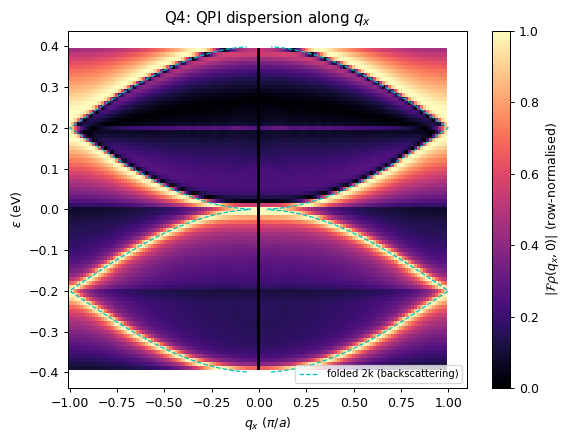

In [15]:
energies_cut = np.linspace(-0.39, 0.39, 79)
cut = np.empty((len(energies_cut), N_qpi))
for i, e in enumerate(energies_cut):
    rho, _ = ldos_with_defect(e)
    line = np.fft.fftshift(np.abs(np.fft.fft2(rho - rho.mean()))[:, 0])    # q_y = 0
    cut[i] = line / line.max()
q_axis = np.fft.fftshift(2.0 * np.fft.fftfreq(N_qpi))

e_th = np.linspace(-0.399, 0.399, 800)
k_th = np.where(e_th < 0, np.arccos(np.clip(-1 - e_th/(2*t), -1, 1)), np.arccos(np.clip(1 - e_th/(2*t), -1, 1)))
q_th = np.abs(fold(2 * k_th)) / np.pi

fig, ax = plt.subplots(figsize=(6.5, 5))
pc = ax.pcolormesh(q_axis, energies_cut, cut, shading="auto", cmap="magma")
for s in (+1, -1):
    ax.plot(s * q_th, e_th, "c--", lw=1, label="folded 2k (backscattering)" if s > 0 else None)
fig.colorbar(pc, ax=ax, label=r"$|\mathcal{F}\rho(q_x,0)|$ (row-normalised)")
ax.set_xlabel(r"$q_x$ ($\pi/a$)"); ax.set_ylabel(r"$\varepsilon$ (eV)")
ax.set_title("Q4: QPI dispersion along $q_x$"); ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig("Q4_qpi_dispersion.png", dpi=200); plt.show()

## 4.7 Dependence on the defect potential, and the $\pm\varepsilon$ symmetry

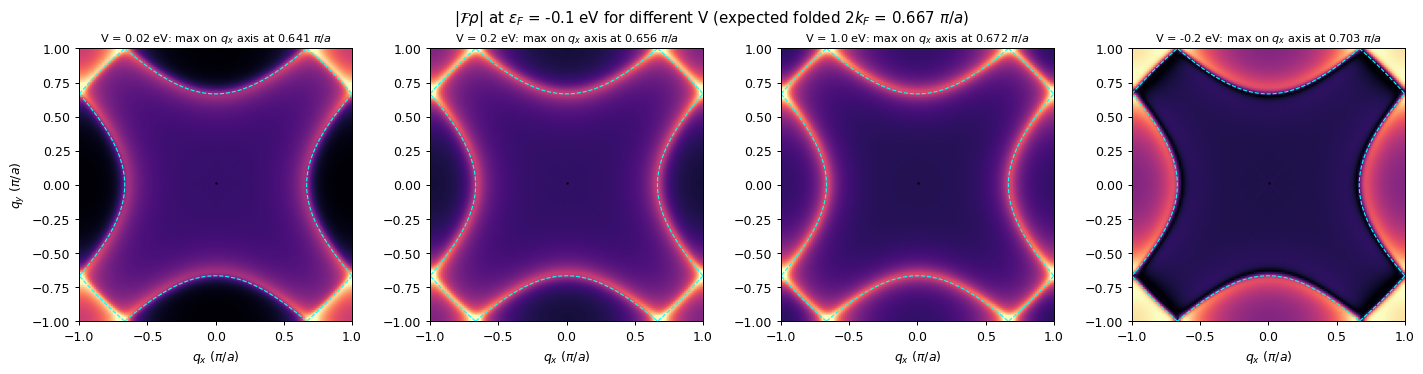

max |rho_V(r,+0.1) - rho_-V(r,-0.1)| = 4.4e-16
max |rho_V(r,+0.25) - rho_-V(r,-0.25)| = 3.3e-16


In [16]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
q_axis = np.fft.fftshift(2.0 * np.fft.fftfreq(N_qpi))
for ax, Vt in zip(axs, [0.02, 0.2, 1.0, -0.2]):
    rho, _ = ldos_with_defect(eps_F, V=Vt)
    F, q = fourier_map(rho)
    ax.imshow(F.T, origin="lower", cmap="magma", extent=[-1, 1, -1, 1], vmin=0, vmax=np.percentile(F, 99.5))
    draw_folded_2k(ax, eps_F)
    line = np.abs(np.fft.fft2(rho - rho.mean()))[1:N_qpi//2, 0]
    ax.set_title(f"V = {Vt} eV: max on $q_x$ axis at {2*(np.argmax(line)+1)/N_qpi:.3f} $\\pi/a$", fontsize=9)
    ax.set_xlabel(r"$q_x$ ($\pi/a$)")
axs[0].set_ylabel(r"$q_y$ ($\pi/a$)")
fig.suptitle(rf"$|\mathcal{{F}}\rho|$ at $\varepsilon_F$ = {eps_F} eV for different V (expected folded $2k_F$ = 0.667 $\pi/a$)")
fig.tight_layout(); fig.savefig("Q4_V_dependence.png", dpi=200); plt.show()

# Exact identity rho_V(r, eps) = rho_{-V}(r, -eps), from particle-hole symmetry (see 4.9)
for e in [0.1, 0.25]:
    d = np.max(np.abs(ldos_with_defect(e, V=V)[0] - ldos_with_defect(-e, V=-V)[0]))
    print(f"max |rho_V(r,{e:+}) - rho_-V(r,{-e:+})| = {d:.1e}")

## 4.8 Convergence checks

In [17]:
def centred(rho, w):
    N = rho.shape[0]; x = np.arange(-N//2, N//2); s = np.abs(x) <= w
    return np.fft.fftshift(rho)[np.ix_(s, s)]

for e in [eps_F, 0.0]:
    r128 = centred(ldos_with_defect(e, N=128)[0], 20)
    r256 = centred(ldos_with_defect(e, N=256)[0], 20)
    r_eta = centred(ldos_with_defect(e, N=256, eta=0.005)[0], 20)
    sig = np.std(r256)
    print(f"eps = {e:+.2f} eV: |N=128 - N=256| = {np.max(np.abs(r128 - r256))/sig:.1%} of signal;  "
          f"|eta=0.01 - eta=0.005| (N=256) = {np.max(np.abs(r256 - r_eta))/sig:.0%} of signal")

# Does eta move the QPI wavevector? Strongest point on the q_x axis at eps_F
for N, et in [(128, 0.01), (256, 0.01), (256, 0.005)]:
    rho, _ = ldos_with_defect(eps_F, N=N, eta=et)
    line = np.abs(np.fft.fft2(rho - rho.mean()))[1:N//2, 0]
    print(f"N = {N}, eta = {et}: strongest q_x = {2*(np.argmax(line)+1)/N:.3f} pi/a   (folded 2k_F = 0.667)")

eps = -0.10 eV: |N=128 - N=256| = 2.3% of signal;  |eta=0.01 - eta=0.005| (N=256) = 58% of signal
eps = +0.00 eV: |N=128 - N=256| = 3.2% of signal;  |eta=0.01 - eta=0.005| (N=256) = 574% of signal
N = 128, eta = 0.01: strongest q_x = 0.656 pi/a   (folded 2k_F = 0.667)
N = 256, eta = 0.01: strongest q_x = 0.656 pi/a   (folded 2k_F = 0.667)
N = 256, eta = 0.005: strongest q_x = 0.664 pi/a   (folded 2k_F = 0.667)


**Grid size.** Going from $N=128$ to $N=256$ changes the LDOS within $\pm20$ sites by only a few per cent of the signal. So $N=128$ is adequate, and the periodic images of the defect do not matter.

**Broadening.** Halving $\eta$ changes the maps substantially: by about 60% of the signal at $\varepsilon_F$, and by several times the signal at $\varepsilon=0$. There are two reasons. First, $\ell_\eta$ doubles, so the oscillations extend further from the defect. Second, at $\varepsilon=0$ both the van Hove peak and the diagonal beams are limited only by $\eta$.

It does **not** move the QPI wavevector. The strongest point on the $q_x$ axis moves from $0.656$ to $0.664\,\pi/a$, i.e. *towards* the predicted folded $2k_F = 0.667\,\pi/a$, as the features sharpen. This is expected: $\eta$ sets the coherence length and the feature widths, while the band structure sets the wavevectors.

---
## 4.9 Answer: discussion of the energy dependence

**General rule, confirmed at every energy.** In panels (d), the QPI features always lie on the folded $2\mathbf{k}$ contour of the constant-energy contour at that energy. So changing the bias energy in an STM experiment scans through constant-energy contours of the band. The energy–momentum cut in 4.6 shows this most compactly: the QPI maxima follow $q(\varepsilon)=2k(\varepsilon)$, which is the band dispersion $\varepsilon(k)$ of Q1 with the momentum axis stretched by 2. This is how QPI is used to measure band structures.

**$\varepsilon=-0.35$ eV (near the band bottom).**
- *Contour:* a small, almost circular contour around $\Gamma$, with $k\approx0.23\pi/a$ along the axes.
- *QPI:* an almost isotropic ring of radius $2k\approx0.46\pi/a$.
- *Real space:* nearly circular Friedel rings with period $\pi/k\approx4.3$ sites. This is the free-electron-like regime, where the parabolic expansion near $\Gamma$ holds.

**$\varepsilon=-0.2$ eV.**
- *Contour:* larger and visibly squarish.
- *QPI:* along the axes, $k=\pi/2a$, so $2k=\pi/a$. The QPI contour just touches the zone boundary. The real-space wavefronts become square-like.

**$\varepsilon=-0.1$ eV ($\varepsilon_F$).** Discussed in 4.4. Along the axes, $2k$ now exceeds the zone and folds back. As a result, the real-space wavelength along $x$ *increases* again (3 sites), even though $k$ has grown. This is aliasing on the discrete lattice.

**$\varepsilon=0$ (half filling, van Hove singularity, perfect nesting).**
- *Contour:* the square $|k_x|+|k_y|=\pi$.
- *QPI:* its $2\mathbf{k}$ image folds onto the diagonals $q_x=\pm q_y$. All points on a flat edge share the same velocity direction, $(\pm1,\pm1)/\sqrt2$. So the stationary-phase "focusing" is extreme.
- *Real space:* narrow **beams along the diagonals**. These decay only through $\eta$ (no $1/\sqrt r$ spreading) and have alternating sign across the beam. They are the real-space counterpart of the nesting vector $\mathbf{Q}=(\pi,\pi)$ and of the diverging Lindhard susceptibility discussed in Section 6 of the notes.
- *Strongest QPI weight:* at the zone corners, $\mathbf{q}\approx(\pm\pi,\pm\pi)/a = \mathbf{Q}$, where the folded diagonals meet.
- *Signal strength:* the clean LDOS is maximal here ($\rho_0 = 2.57$ eV$^{-1}$), and $|VG_0(0)|$ is largest.

**$\varepsilon=+0.1$ and $+0.2$ eV (hole pockets around $X$).**
- *Contour:* encloses $X=(\pi,\pi)$ (Lifshitz transition at $\varepsilon=0$).
- *QPI:* backscattering across a pocket, $\mathbf{X}+\mathbf{p}\to\mathbf{X}-\mathbf{p}$, gives $\mathbf{q}=2\mathbf{p}$. So the QPI contours are centred on $\mathbf{q}=0$ and **coincide with those at $-\varepsilon$**, as the cut in 4.6 shows.
- *Why the maps still look different from those at $-\varepsilon$:* particle–hole symmetry implies the exact identity
$$\rho_V(\mathbf{r},\varepsilon)=\rho_{-V}(\mathbf{r},-\varepsilon)$$
(checked numerically to $10^{-16}$ in 4.7). So a repulsive defect at $+\varepsilon$ looks exactly like an attractive defect at $-\varepsilon$. The *positions* of the features are fixed by the band. Their *contrast* (peak, dip or step) is set by the complex phase of $T$, which differs between $\pm\varepsilon$ for fixed $V$.
- *Born limit:* in the Born limit $T\approx V$, and the identity becomes $\delta\rho(\mathbf{r},\varepsilon)=-\delta\rho(\mathbf{r},-\varepsilon)$, with identical $|\mathcal{F}\rho|$ at $\pm\varepsilon$.

**Dependence on $V$ (4.7).** Varying $V$ from $0.02$ to $1$ eV, or changing its sign, leaves the QPI contours in place. The strongest point on the $q_x$ axis stays within about $0.04\,\pi/a$ of $0.667\,\pi/a$ (see the panel titles). That is two to three grid spacings of $2/N = 0.016\,\pi/a$, and the exact position depends on whether the feature shows up as a peak or a step. Only the intensity and line shape change, through $\mathrm{Im}[T\Lambda]$. This confirms that QPI wavevectors are a property of the clean band structure, not of the defect.

## Summary of key numbers

| Quantity | Value |
|---|---|
| Bandwidth | $8t = 0.8$ eV (band from $-0.4$ to $+0.4$ eV) |
| Spectral-function peak / FWHM | $1/(\pi\eta)=31.8$ eV$^{-1}$ / $2\eta=0.02$ eV |
| DOS band-edge step | $1/(4\pi t)=0.80$ eV$^{-1}$ per site per spin |
| DOS at van Hove ($\eta$-limited) | $\ln(16t/\eta)/(2\pi^2t)=2.57$ eV$^{-1}$ |
| Convergence criterion | $N\gtrsim4\pi t/\eta\approx126$ |
| $k_F$ at $\varepsilon_F=-0.1$ eV | $0.667\,\pi/a$ (axis), $(0.42,0.42)\,\pi/a$ (diagonal) |
| QPI at $\varepsilon_F$ | $2k_F$ folded: $\pm0.667\,\pi/a$ on axes, $(0.84,0.84)\,\pi/a$ on diagonals |
| Real-space periods at $\varepsilon_F$ | 3 sites (axes), 6.2 diagonal steps (diagonals) |